In [128]:
import pandas as pd
import mysql.connector
import os

# List of CSV files and their corresponding table names
csv_files = [
    ('customers.csv', 'customers'),
    ('orders.csv', 'orders'),
    ('sellers.csv', 'sellers'),
    ('products.csv', 'products'),
    ('geolocation.csv', 'geolocation'),
    ('payments.csv', 'payments'),
    ('order_items.csv','order_items')
    # Added payments.csv for specific handling
]

# Connect to the MySQL database

conn = mysql.connector.connect(
    host='localhost',
    user='root',
    port="3306",
    password='root1234',
    database='ecommerce'
)
cursor = conn.cursor()

# Folder containing the CSV files
folder_path = 'C:/Users/DELL/Downloads/Ecommerce'

def get_sql_type(dtype):
    if pd.api.types.is_integer_dtype(dtype):
        return 'INT'
    elif pd.api.types.is_float_dtype(dtype):
        return 'FLOAT'
    elif pd.api.types.is_bool_dtype(dtype):
        return 'BOOLEAN'
    elif pd.api.types.is_datetime64_any_dtype(dtype):
        return 'DATETIME'
    else:
        return 'TEXT'

for csv_file, table_name in csv_files:
    file_path = os.path.join(folder_path, csv_file)
    
    # Read the CSV file into a pandas DataFrame
    df = pd.read_csv(file_path)
    
    # Replace NaN with None to handle SQL NULL
    df = df.where(pd.notnull(df), None)
    
    # Debugging: Check for NaN values
    print(f"Processing {csv_file}")
    print(f"NaN values before replacement:\n{df.isnull().sum()}\n")

    # Clean column names
    df.columns = [col.replace(' ', '_').replace('-', '_').replace('.', '_') for col in df.columns]

    # Generate the CREATE TABLE statement with appropriate data types
    
    columns = ', '.join([f'`{col}` {get_sql_type(df[col].dtype)}' for col in df.columns])
    create_table_query = f'CREATE TABLE IF NOT EXISTS `{table_name}` ({columns})'
    cursor.execute(create_table_query)

    # Insert DataFrame data into the MySQL table
    for _, row in df.iterrows():
        # Convert row to tuple and handle NaN/None explicitly
        values = tuple(None if pd.isna(x) else x for x in row)
        sql = f"INSERT INTO `{table_name}` ({', '.join(['`' + col + '`' for col in df.columns])}) VALUES ({', '.join(['%s'] * len(row))})"
        cursor.execute(sql, values)

    # Commit the transaction for the current CSV file
    conn.commit()

# Close the connection
#conn.close()

Processing customers.csv
NaN values before replacement:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Processing orders.csv
NaN values before replacement:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 585
order_delivered_carrier_date     7767
order_delivered_customer_date    8848
order_estimated_delivery_date       0
dtype: int64

Processing sellers.csv
NaN values before replacement:
seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

Processing products.csv
NaN values before replacement:
product_id                    0
product_category              0
product_name_length           0
product_description_length    0
product_photos_qty            0
product_weight

KeyboardInterrupt: 

In [ ]:
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root1234",
    port=3306,
    database="ecommerce"
)

cursor = conn.cursor()

print("Connection successful:", conn.is_connected())

In [ ]:
query="""select distinct customer_city from customers"""
cursor.execute(query)
data=cursor.fetchall()
data


In [ ]:

query="""select count(order_id) from orders where year(order_purchase_timestamp)=2017"""
cursor.execute(query)
data=cursor.fetchall()
print("Total orders placr in 2017 is",data[0][0])

In [149]:
# find total sales per category
import mysql.connector

conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root1234",
    port=3306,
    database="ecommerce"
)

cursor = conn.cursor()
#cur.db.cursor()
print(cursor)

print("Connection successful:", conn.is_connected())

query="""select products.product_category category,sum(payments.payment_value) sales
from products
join order_items
on products.product_id=order_items.product_id
join payments
on payments.order_id=order_items.order_id
group by category """

cursor.execute(query)
data=cursor.fetchall()
data

MySQLCursor: (Nothing executed yet)
Connection successful: True


[('Art', 1192866.9393424988),
 ('electronics', 1212068.1200942993),
 ('sport leisure', 1135108.2405548096),
 ('CONSTRUCTION SECURITY', 1172186.2407112122),
 ('Furniture Decoration', 1204720.8200035095),
 ('musical instruments', 1124901.5189380646),
 ('telephony', 1164217.6998500824),
 ('perfumery', 1185008.1400928497),
 ('auto', 1148270.9998455048),
 ('home appliances', 1214934.0195350647),
 ('babies', 1127680.4586753845),
 ('garden tools', 1182649.559310913),
 ('watches gifts', 1168853.2201519012),
 ('computer accessories', 1173585.5791015625),
 ('fashion bags accessories', 1196878.0197696686),
 ('stationery', 1160934.0796375275),
 ('health beauty', 1138907.3996219635),
 ('pet shop', 1175330.2188034058),
 ('books', 1155137.7402744293),
 ('toys', 1254187.8592643738),
 ('food', 1192454.580286026),
 ('Cool Stuff', 1133904.1592178345),
 ('housewares', 1181147.899755478),
 ('bed table bath', 1242299.7411270142)]

In [ ]:
query = """
WITH order_totals AS (
    SELECT
        order_id,
        SUM(price) AS total_order_price
    FROM order_items
    GROUP BY order_id
),
category_sales AS (
    SELECT
        p.product_category AS category,
        SUM(
            pay.payment_value * oi.price / NULLIF(ot.total_order_price, 0)
        ) AS sales
    FROM products p
    JOIN order_items oi
        ON p.product_id = oi.product_id
    JOIN order_totals ot
        ON oi.order_id = ot.order_id
    JOIN (
        SELECT order_id, SUM(payment_value) AS payment_value
        FROM payments
        GROUP BY order_id
    ) pay
        ON oi.order_id = pay.order_id
    GROUP BY p.product_category
)
SELECT category, sales
FROM category_sales
ORDER BY sales DESC
"""

cursor.execute(query)
data = cursor.fetchall()
data

In [ ]:
# Find total sales per category 

query="""select products.product_category,sum(payments.payment_value) sales
from products join
on products.product_id=order_items.product_id
join payments
on payments.order_id=order_items.order_id
group by category"""
conn.execute(query)
data=conn.fetchall()
data 

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
#import matplolib as plt
import mysql.connector
db=mysql.connector.connect(host      = "localhost",
                           username = "root",
                           password  = "root1234",
                           database  = "ecommerce"
                          )
cur=db.cursor()


In [ ]:
query="""select upper(products.product_category),round(sum(payments.payment_value),2) sales
from products join order_items
on products.product_id=order_items.product_id
join payments
on payments.order_id=order_items.order_id
group by product_category"""
cur.execute(query)
data=cur.fetchall()
data 
df=pd.DataFrame(data,columns =["Category","Sales"])
df

In [ ]:
# Calculate persentage of orders that were paid in installments

qeury="""select (sum(case when payment_installments>=1 then 1
else 0 end))/count(*)*100 from payments"""
cur.execute(qeury)
data=cur.fetchall()
data

In [ ]:




#count the number of customer of each state
query="""select customer_state,count(customer_id)
from customers group by customer_state"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["State","Customer_count"])
df
plt.bar(df["State"],df["Customer_count"])
df=df.sort_values(by = "Customer_count",ascending=False)
plt.xlabel("State")
plt.ylabel("Customer Count")
plt.title("Customer Count by State")
plt.figure(figsize=(8,2))
#plt.xticks(rotation=60)
plt


In [ ]:
#pip install matplotlib
import matplotlib
import matplotlib.pyplot as plt

In [ ]:
plt.bar(df["State"],df["Customer_count"])
df=df.sort_values(by = "Customer_count",ascending=False)
plt.xlabel("State")
plt.ylabel("Customer Count")
plt.title("Customer Count by State")
plt.figure(figsize=(8,2))
#plt.xticks(rotation=60)
plt

In [ ]:
# calculate the numbers of order per month in 2018

query="""select monthname(order_purchase_timestamp)Months ,count(order_id) from orders where year(order_purchase_timestamp)=2018
group by Months"""
cur.execute(query)
data=cur.fetchall()
data

df=pd.DataFrame(data ,columns=["Months","Order_count"])
r=["January","February","March","April","May","June","July","August","Septber","October","DEC"]
ax=sns.barplot(x=df["Months"],y=df["Order_count"],data=df,order=rcolor="RED")
df
plt.bar(df["Months"],df["Order_count"])
plt.xticks(rotation=45)
ax.bar_label(ax.containers[0])
df=df.sort_values(by = "Order_count",ascending=False)
plt.title("Count of orders by months in 2018")

plt

In [ ]:
# find the avarage number of product per order ,group by customer city
query="""with count_per_order as( select orders.order_id,orders.customer_id,round(count(order_items.order_id),2)count_order
from orders join order_items
on orders.order_id=order_items.order_id
group by orders.order_id,orders.customer_id)

select customers.customer_city,avg(count_per_order.count_order)avg_orders
from customers join count_per_order
on customers.customer_id=count_per_order.customer_id
group by customers.customer_city order by avg_orders desc"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["city","avg_of_city_order"])
df
data1=df.head()
data1


In [ ]:
# calculate the percentage of total revenue contribute by each product category
query=""" select upper( products.product_category)category,round((sum(payments.payment_value)/(select sum(payment_value) from payments))*100,2) order_per_by_category
from products join order_items
on products.product_id=order_items.product_id
join payments
on payments.order_id=order_items.order_id
group by products.product_category order by order_per_by_category desc"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["category","percentage"])
df
df.head()

In [ ]:
query="""select products.product_category,count(order_items.order_id),
round(avg(order_items.price),2)
from products join order_items
on products.product_id=order_items.product_id
group by products.product_category"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["Category","order_count","price"])
df

import numpy as np
arr1=df["order_count"]
arr2=df["price"]
np.corrcoef([arr1,arr2])

In [29]:
import mysql.connector
db=mysql.connector.connect(host      = "localhost",
                           username = "root",
                           password  = "root1234",
                           database  = "ecommerce"
                          )
cur=db.cursor()


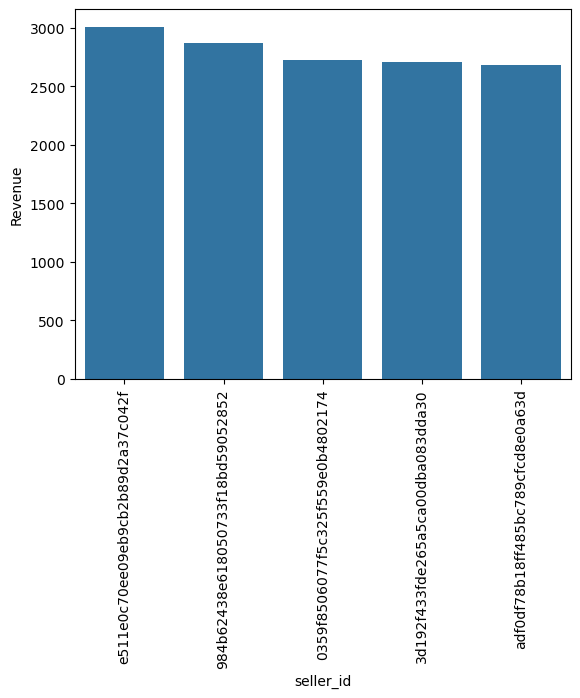

In [191]:
query="""select *,dense_rank()over(order by total_rv desc) from(
select order_items.seller_id,round(sum(payments.payment_value),2) total_RV
from order_items join payments
on order_items.order_id=payments.order_id
group by order_items.seller_id)as a"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["seller_id","Revenue","Price"])
df=df.head()
sns.barplot(x="seller_id",y="Revenue",data=df)
plt.xticks(rotation=90)
plt.show()

In [11]:
#calculate the moving avarage of orders value of each  customer over their order history
import pandas as pd
query="""select customer_id,order_purchase_timestamp,price,
avg(price)over(partition by customer_id order by order_purchase_timestamp
rows between 2 preceding and current row) as mov_avg
from(select orders.customer_id,orders.order_purchase_timestamp,payments.payment_value as price
from payments join orders
on payments.order_id=orders.order_id) as a"""

cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns= ["Customer_id","order_purchase_date","price","mov_avg"])
df


,Customer_id,order_purchase_date,price,mov_avg
0,00004bc31d073986a38539e58f63cf70,2017-10-13 18:36:51,118.79,118.790001
1,00004bc31d073986a38539e58f63cf70,2017-10-13 18:36:51,118.79,118.790001
2,00004bc31d073986a38539e58f63cf70,2017-10-13 18:36:51,118.79,118.790001
3,00004bc31d073986a38539e58f63cf70,2017-10-13 18:36:51,118.79,118.790001
4,0001a923e7644588bb8406987bc17c07,2017-09-11 05:48:48,86.15,86.150002
...,...,...,...,...
399995,fffd7e247b69e79fccf4decbffd8795c,2017-08-17 06:02:44,634.25,634.250000
399996,ffffd8f615e1e835628300ac6d30a674,2018-08-16 10:32:49,54.31,54.310001
399997,ffffd8f615e1e835628300ac6d30a674,2018-08-16 10:32:49,54.31,54.310001
399998,ffffd8f615e1e835628300ac6d30a674,2018-08-16 10:32:49,54.31,54.310001


In [17]:
# calculate the runing total or cumulative sales per month of each year
query="""select years,months,Total_payment,sum(Total_payment)
over(order by years,months) as cumulative_sales
from(select year(orders.order_purchase_timestamp) years,
month(orders.order_purchase_timestamp)months,
round(sum(payments.payment_value),2) as Total_payment
from orders join payments
on orders.order_id = payments.order_id
group by years,months order by years,months desc)as a"""
cur.execute(query)
data=cur.fetchall()
data


[(2017, 1, 2800644.72, 2800644.72),
 (2017, 2, 2500621.36, 5301266.08),
 (2017, 3, 2798572.44, 8099838.52),
 (2017, 4, 2610095.08, 10709933.6),
 (2017, 5, 2752972.48, 13462906.08),
 (2017, 6, 2567310.16, 16030216.24),
 (2017, 7, 2823076.6, 18853292.84),
 (2017, 8, 2820703.0, 21673995.84),
 (2017, 9, 2699903.36, 24373899.2),
 (2017, 10, 2790387.44, 27164286.64),
 (2017, 11, 2728242.32, 29892528.96),
 (2017, 12, 2767164.0, 32659692.96),
 (2018, 1, 2683908.2, 35343601.160000004),
 (2018, 2, 2500015.56, 37843616.720000006),
 (2018, 3, 2791973.96, 40635590.68000001),
 (2018, 4, 2671818.64, 43307409.32000001),
 (2018, 5, 2731846.44, 46039255.760000005),
 (2018, 6, 2749019.08, 48788274.84),
 (2018, 7, 2881450.2, 51669725.04000001),
 (2018, 8, 1715807.36, 53385532.400000006)]

In [45]:
query="""select year(orders.order_purchase_timestamp) as years, round(sum(payments.payment_value),2) as price
from orders join payments
on orders.order_id = payments.order_id
group by years order by years """

cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["years","sales"])
df

,years,sales
0,2017,32659692.95
1,2018,20725839.44


In [49]:
query="""with a as(select year(orders.order_purchase_timestamp) as years ,sum(payments.payment_value) as Cuurent_price
from orders join payments
on orders.order_id = payments.order_id
group by years order by years)
select years,((Cuurent_price-lag(Cuurent_price) over(order by years ))/
lag(Cuurent_price,1)over(order by years))*100
from a"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data)
df


,0,1
0,2017,NaN
1,2018,-36.540005


In [65]:

query="""

with a as (select month(orders.order_purchase_timestamp) as months,round(sum(payments.payment_value),2) as payment
from orders join payments
on orders.order_id=payments.order_id
group by months order by months)

select months,round(((payment-lag(payment,1)over(order by months))/lag(payment,1)over(order by months))*100,2)
from a;
"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["months","MOM_sales"])
df


,months,MOM_sales
0,1,NaN
1,2,-8.82
2,3,11.80
3,4,-5.52
4,5,3.84
5,6,-3.07
6,7,7.30
7,8,-20.48
8,9,-40.49
9,10,3.35


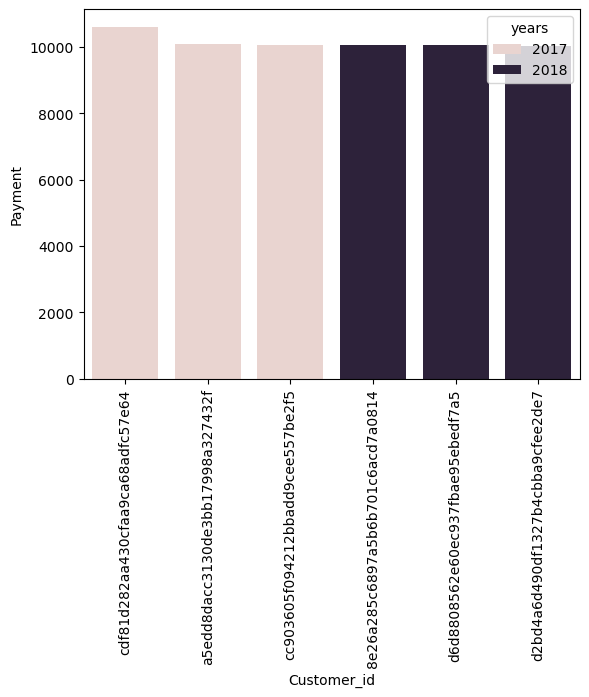

In [79]:
# Identify the top 3 customer who spend the most money in each year
import seaborn as sns
import matplotlib.pyplot as plt
query="""select years,customer_id,payment,d_rank
from
(select year(orders.order_purchase_timestamp)as years,
orders.customer_id,
round(sum(payments.payment_value),2) payment,
dense_rank()over(partition by year(orders.order_purchase_timestamp)
order by sum(payments.payment_value)desc)d_rank
from orders join payments
on orders.order_id=payments.order_id
group by year(orders.order_purchase_timestamp),
orders.customer_id) as a
where d_rank <=3"""
cur.execute(query)
data=cur.fetchall()
data
df=pd.DataFrame(data,columns=["years","Customer_id","Payment","Rank"])
df
sns.barplot(x="Customer_id",y="Payment",data=df,hue="years")
plt.xticks(rotation=90)
plt.show()